# Synthetic score-range banks: weighted score vs accuracy averaged over draws of B

The fresh-pair notebook's view (score against each set's outcome averaged over draws of B) for the
27 other graph settings, now across each bank's full score range instead of random sets only.

- **Banks.** The 27 synthetic cells of the score-range collection: ER, Chung–Lu and PAPER × percolation,
  FAQ and GOAT × three density/ρ settings, each at its calibrated budget on fresh pair 0. Each bank has
  150 seed sets spanning the frozen score: 30 uniform random controls, the hand rules, score endpoints,
  degree-matched contrasts and picks spread across the score range.
- **Outcomes.** Draws 0–2 of B come from the score-range collection; draws 3–10 from
  `score_range_draws.py`. One matcher run per set and draw, with the original solver settings.
- **Averaging.** A set's mean over draws of B is its quality as far as graph A can tell (landscape
  notebook §3–4). Within a bank, means use only draws that every set has finished, so a partly finished
  collection still gives comparable means.

This notebook only reads saved outcomes. Run the collector in a terminal first (`SCORE_RANGE_DRAWS.md`).

In [1]:
from pathlib import Path
import sys
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'experiment_common').is_dir())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
import matplotlib.pyplot as plt
from IPython.display import display
from selection_rule_comparison import score_range_analysis as A
from selection_rule_comparison import score_range_draws_analysis as DA

OUTCOME = 'accuracy_test'   # or 'success': the share of draws on which the run succeeded
SAVE = True                 # figures and tables under data/score_range_draws/analysis

data, runs = DA.load()
inventory = DA.inventory(data, runs)
print(f'Extra-draw files read: {data.extra_files}. Complete draws per bank: '
      f'{inventory.complete_draws.min()} to {inventory.complete_draws.max()} (11 when the collection is finished).')
display(inventory)
frame = DA.per_set(data, runs, OUTCOME)

Extra-draw files read: 216. Complete draws per bank: 11 to 11 (11 when the collection is finished).


,panel,algorithm,sets,complete_draws,draws,extra_runs
0,"Chung–Lu · d=10, ρ=0.4, k=47",goat,150,11,"0,1,2,3,4,5,6,7,8,9,10",1200
1,"Chung–Lu · d=10, ρ=0.5, k=31",faq,150,11,"0,1,2,3,4,5,6,7,8,9,10",1200
2,"Chung–Lu · d=10, ρ=0.5, k=12",goat,150,11,"0,1,2,3,4,5,6,7,8,9,10",1200
3,"Chung–Lu · d=10, ρ=0.7, k=6",percolation,150,11,"0,1,2,3,4,5,6,7,8,9,10",1200
4,"Chung–Lu · d=16, ρ=0.3, k=107",faq,150,11,"0,1,2,3,4,5,6,7,8,9,10",1200
5,"Chung–Lu · d=16, ρ=0.3, k=76",goat,150,11,"0,1,2,3,4,5,6,7,8,9,10",1200
6,"Chung–Lu · d=16, ρ=0.4, k=54",percolation,150,11,"0,1,2,3,4,5,6,7,8,9,10",1200
7,"Chung–Lu · d=32, ρ=0.3, k=53",faq,150,11,"0,1,2,3,4,5,6,7,8,9,10",1200
8,"Chung–Lu · d=32, ρ=0.3, k=89",percolation,150,11,"0,1,2,3,4,5,6,7,8,9,10",1200
9,"PAPER · d=8, ρ=0.4, k=7",goat,150,11,"0,1,2,3,4,5,6,7,8,9,10",1200


## 1. Frozen weighted score vs mean outcome

One figure per graph model. Rows are the matchers; columns are that matcher's three cells, in order of
increasing mean degree.

- **Coloured marks:** each set's mean over every complete draw of B. Colour and shape show how the set was
  built: grey dots are the 30 uniform random controls.
- **Open grey circles:** the same sets on draw 0 alone, the single-B view of the original notebooks.
- **Black line:** the mean within eight equal-count bins of the score, to show the shape of the trend.
- **Text:** Spearman correlation of the score with draw 0 alone, with the mean over draws 0–2, and with
  the mean over all draws; then among the random controls only.

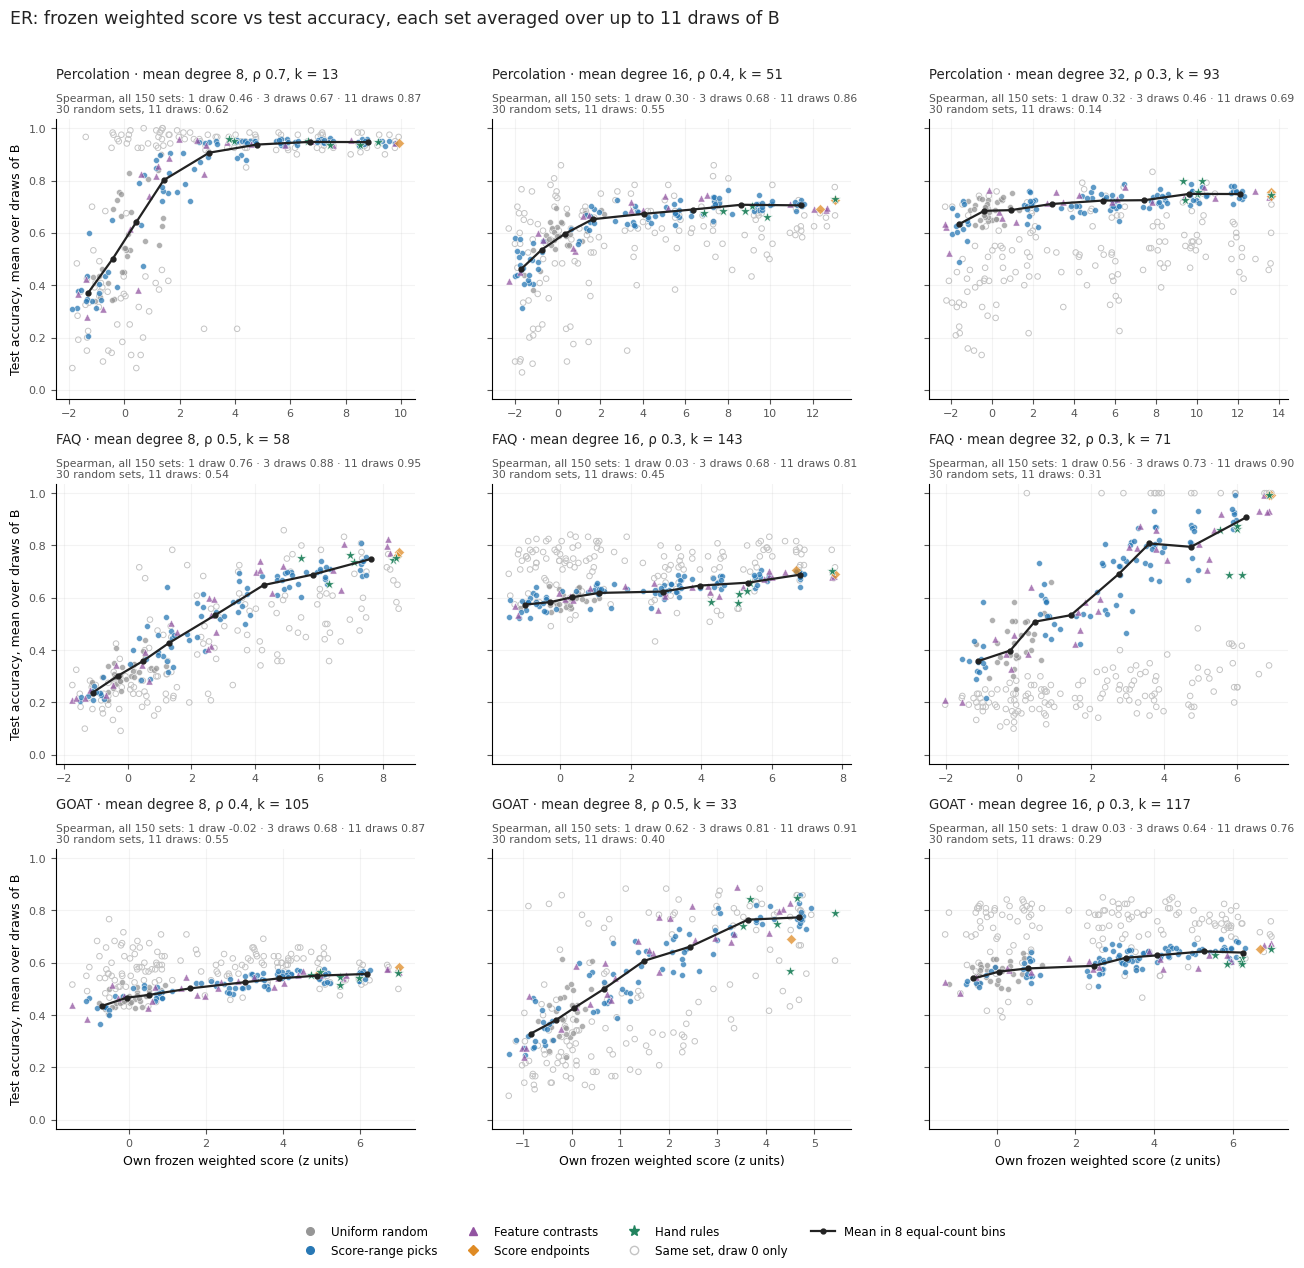

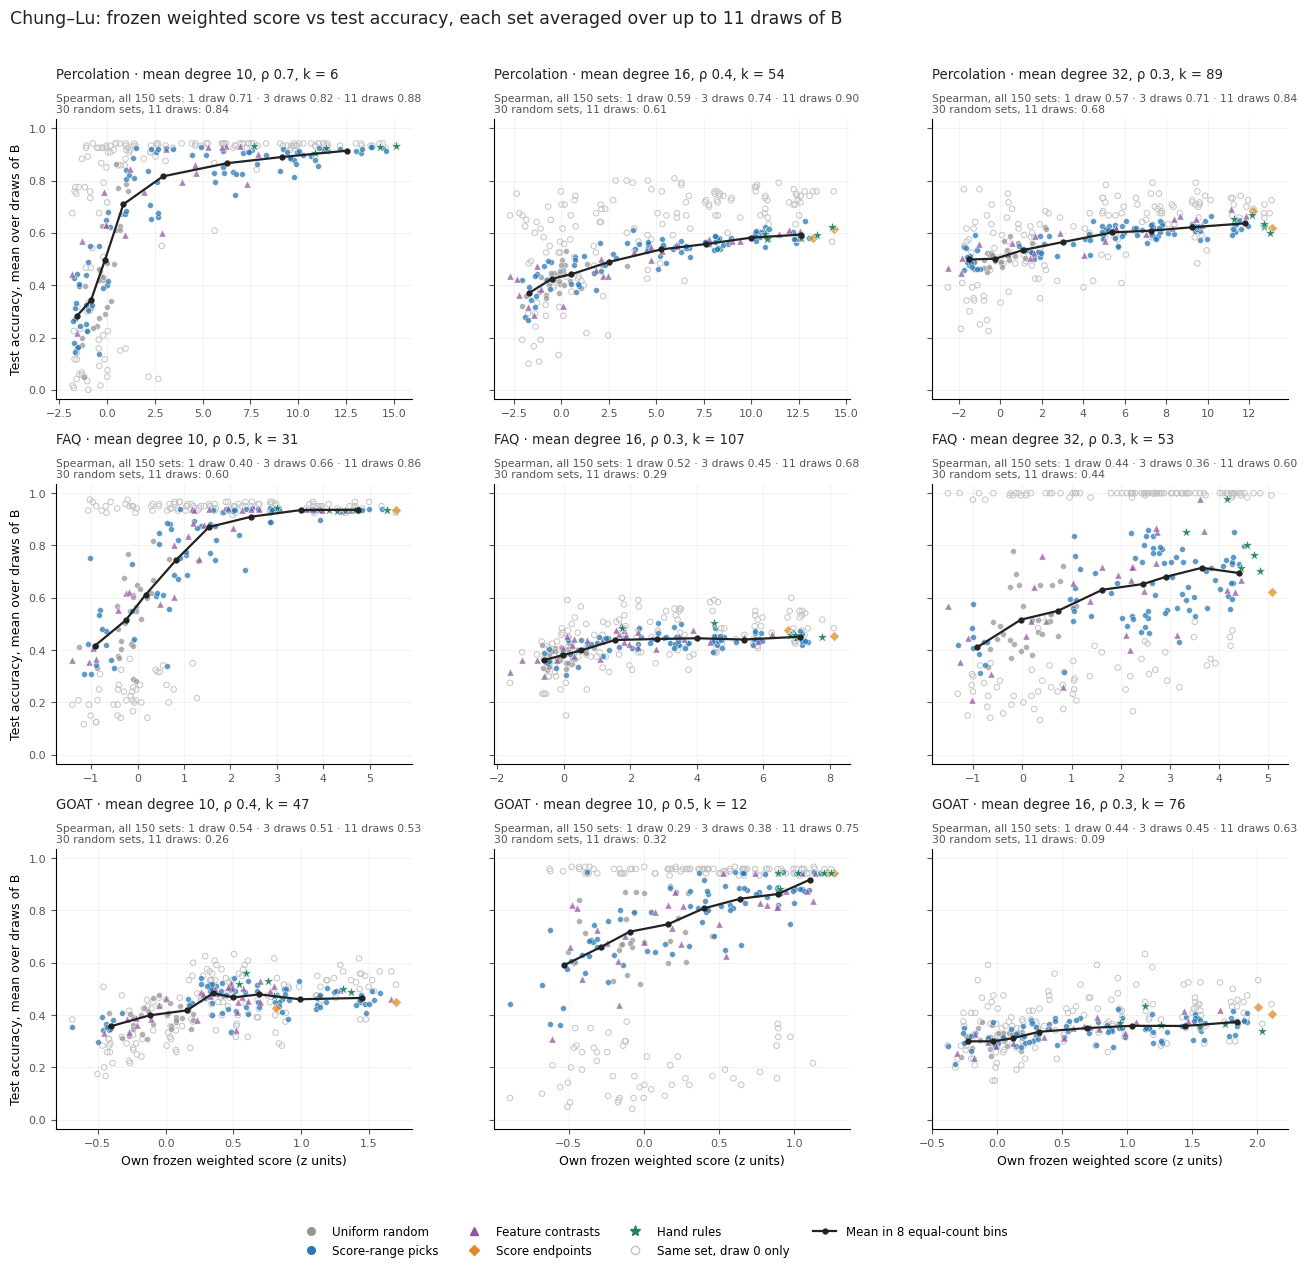

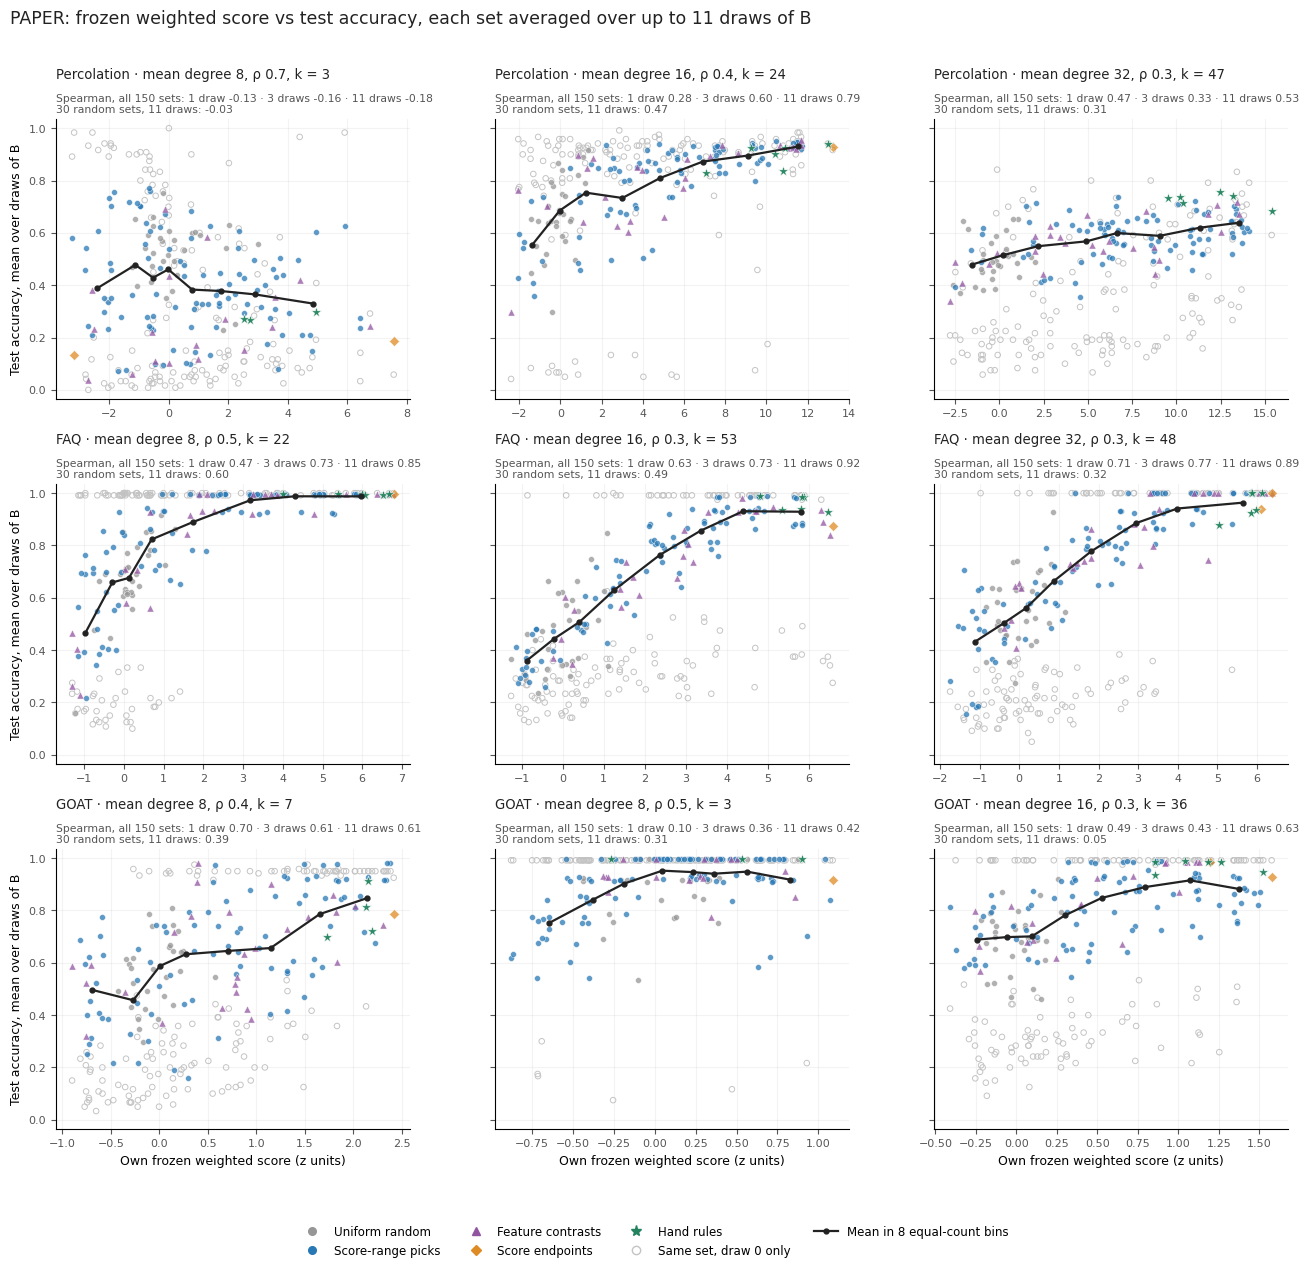

In [2]:
for model in A.MODEL_LABELS:
    fig = DA.plot_model(frame, model, 'frozen_score')
    if SAVE:
        DA.save(fig, f'{model}_frozen_score_{OUTCOME}')
    plt.show()
    plt.close(fig)

## 2. Degree alone

The same layout with the seeds' cut degree (z-score against the bank's random pool) on the x-axis. Where
these figures look like section 1, the weighted score adds little to degree.

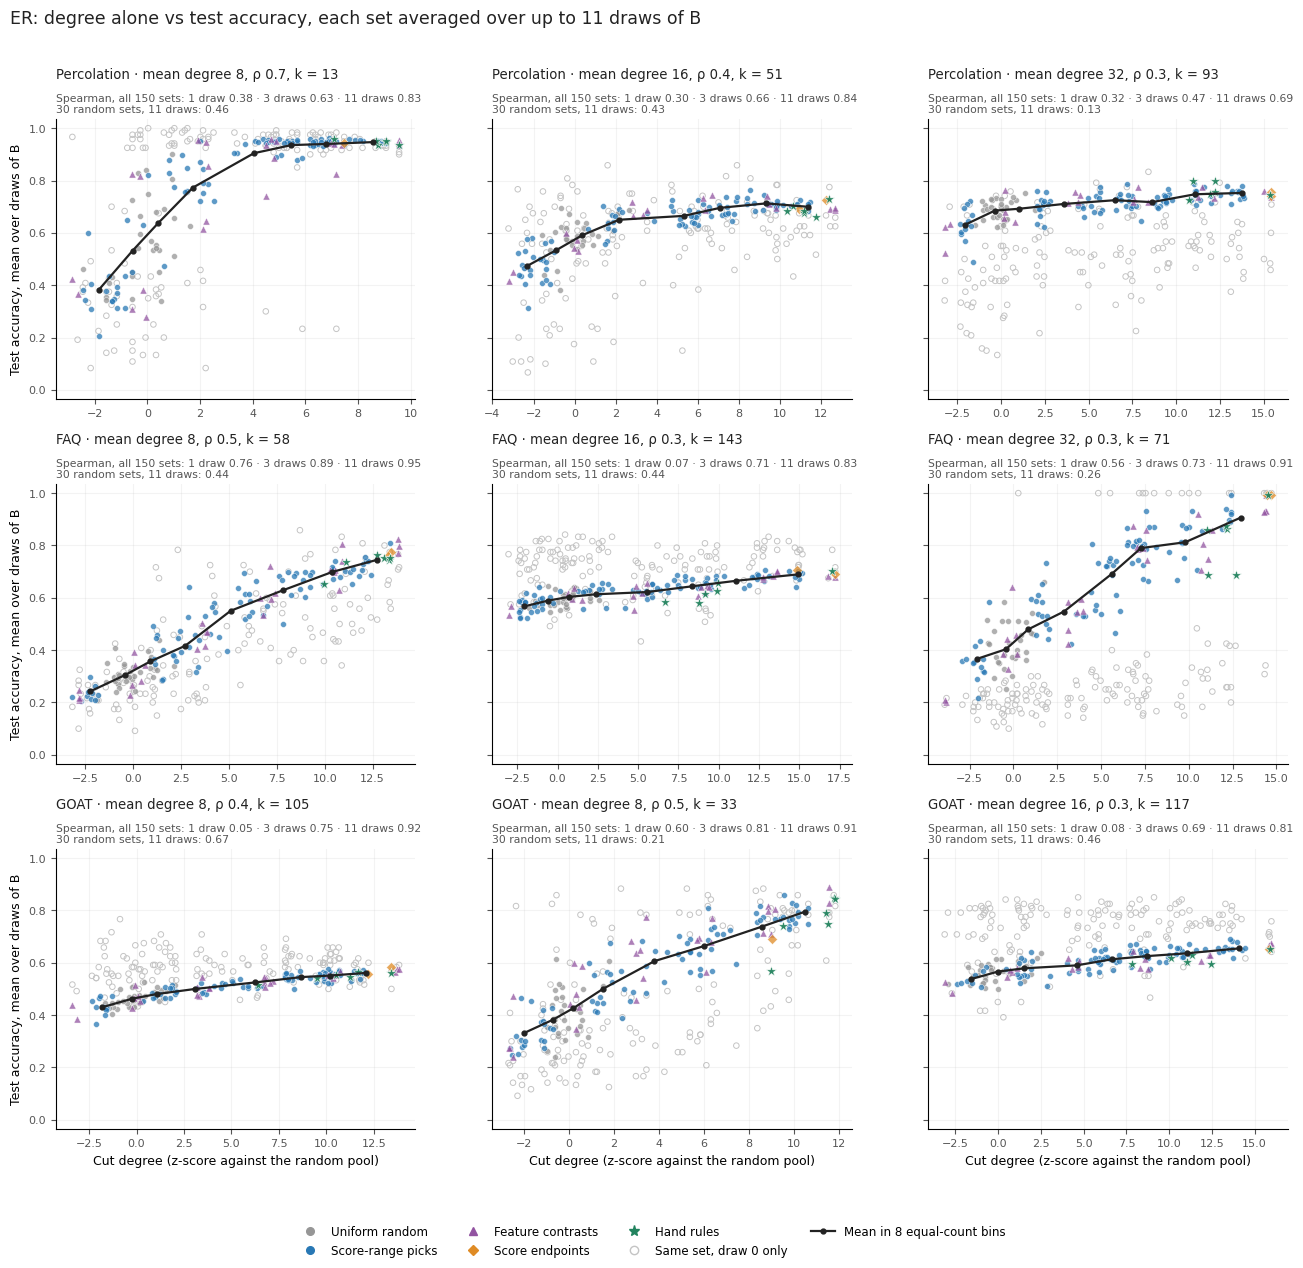

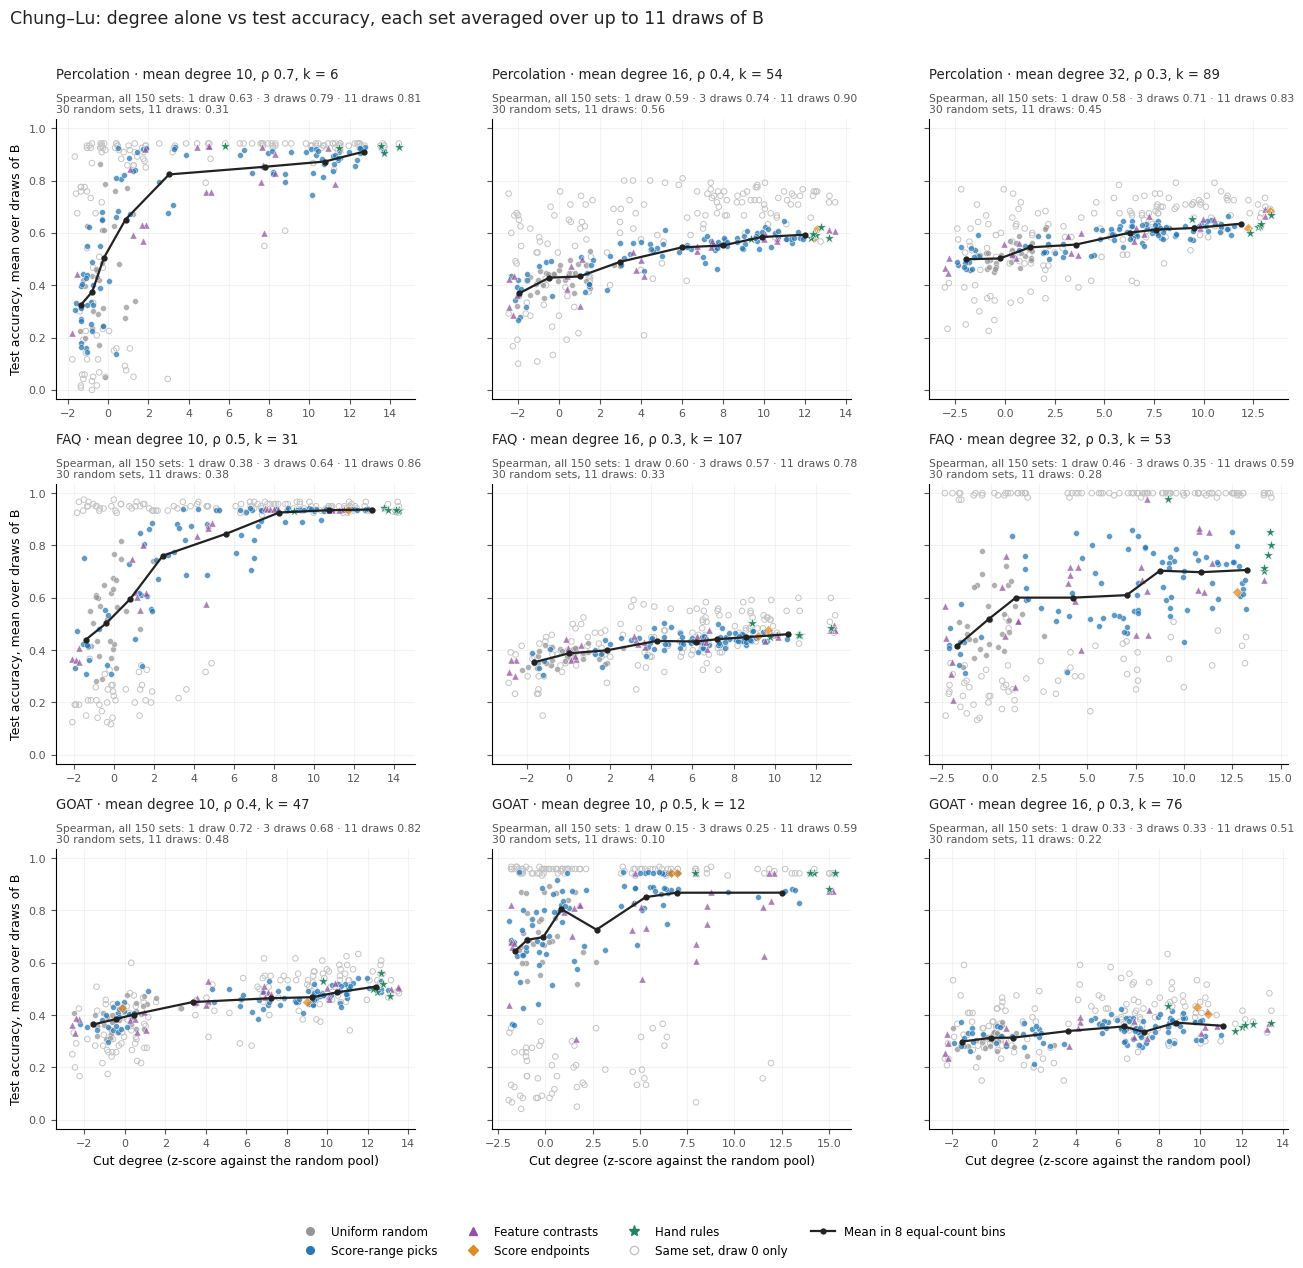

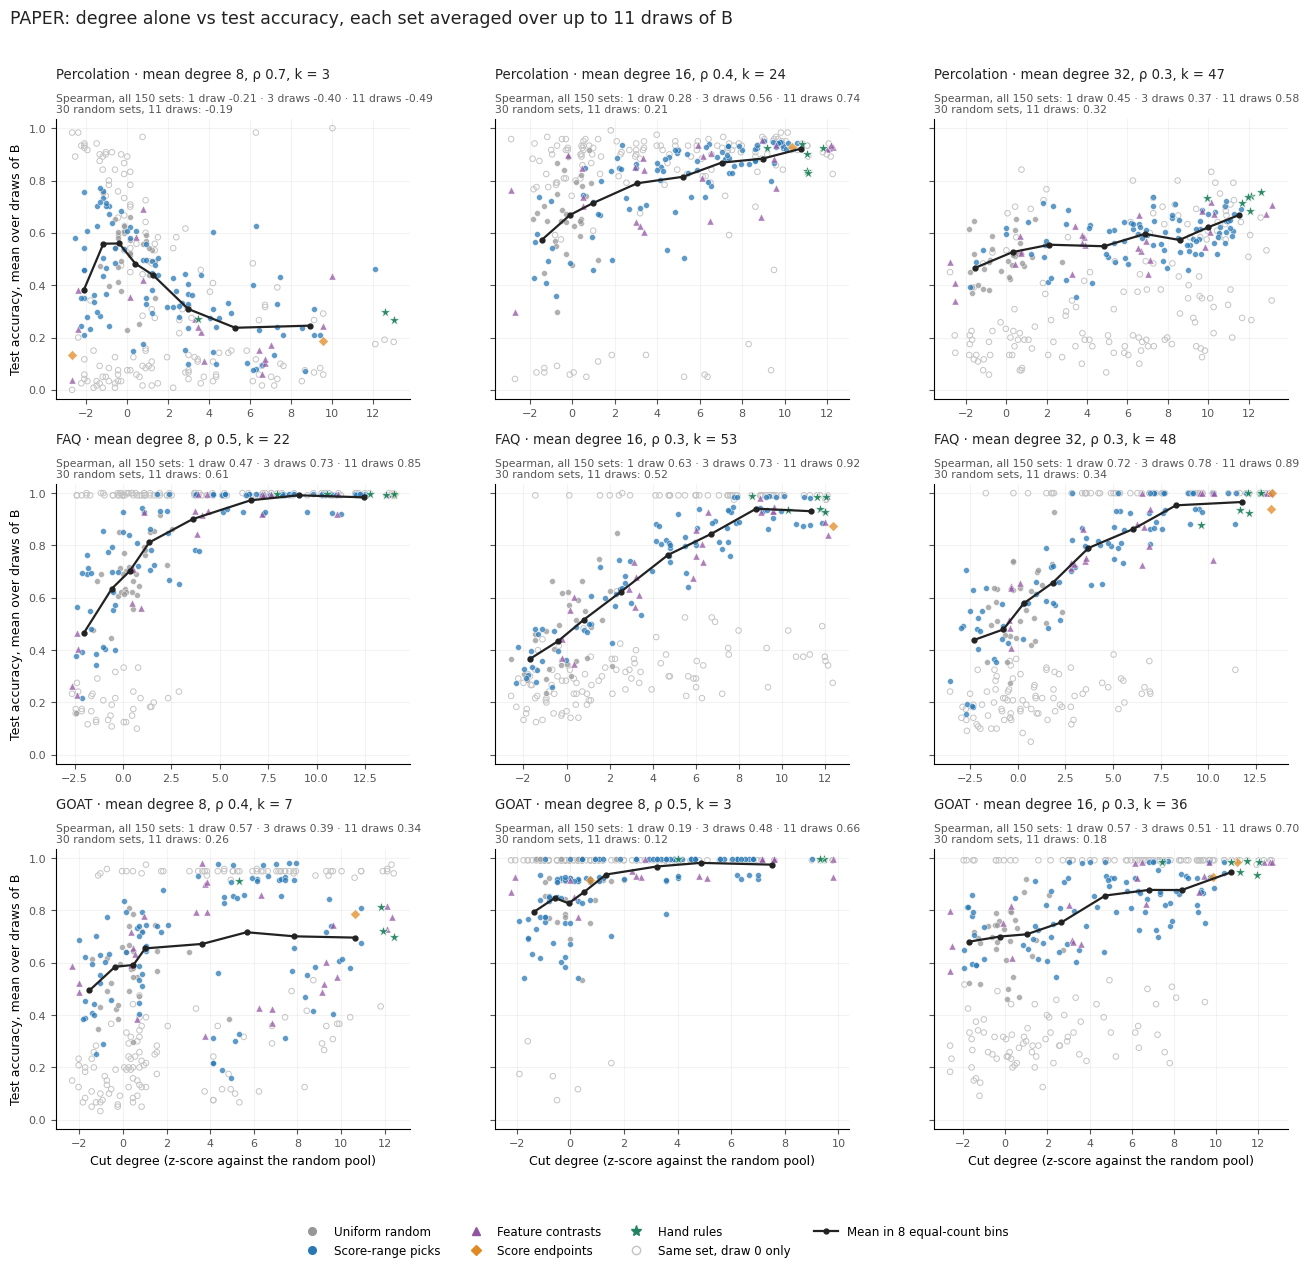

In [3]:
for model in A.MODEL_LABELS:
    fig = DA.plot_model(frame, model, 'z_degree')
    if SAVE:
        DA.save(fig, f'{model}_degree_{OUTCOME}')
    plt.show()
    plt.close(fig)

## 3. Does averaging over more draws sharpen the ranking?

Spearman correlation of the frozen score with each set's mean over the first *m* draws of B, for all sets
in each bank. A line rises while the luck of individual draws averages out; where it levels off, more
draws would change little. Colour is the graph model; line style matches the column in the figures above.
The table below the figure lists the same numbers.

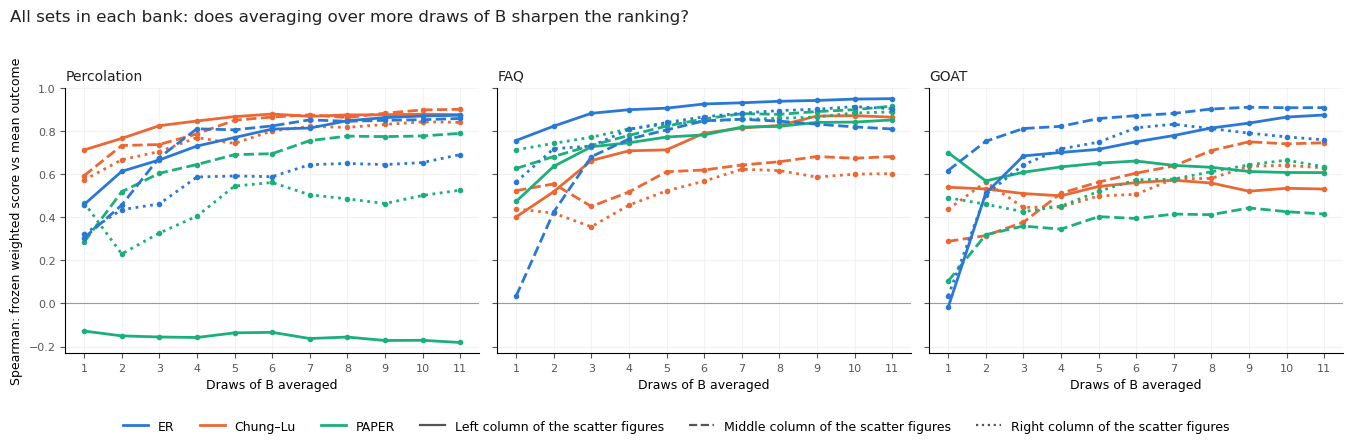

draws                                        1     2     3     4     5     6   \
algorithm   panel                                                               
faq         Chung–Lu · d=10, ρ=0.5, k=31   0.40  0.52  0.66  0.71  0.71  0.79   
            Chung–Lu · d=16, ρ=0.3, k=107  0.52  0.55  0.45  0.52  0.61  0.62   
            Chung–Lu · d=32, ρ=0.3, k=53   0.44  0.42  0.36  0.46  0.52  0.57   
            ER · d=16, ρ=0.3, k=143        0.03  0.42  0.68  0.76  0.81  0.85   
            ER · d=32, ρ=0.3, k=71         0.56  0.72  0.73  0.81  0.84  0.87   
            ER · d=8, ρ=0.5, k=58          0.76  0.82  0.88  0.90  0.91  0.93   
            PAPER · d=16, ρ=0.3, k=53      0.63  0.68  0.73  0.78  0.82  0.86   
            PAPER · d=32, ρ=0.3, k=48      0.71  0.74  0.77  0.81  0.83  0.85   
            PAPER · d=8, ρ=0.5, k=22       0.47  0.64  0.73  0.75  0.77  0.78   
goat        Chung–Lu · d=10, ρ=0.4, k=47   0.54  0.53  0.51  0.50  0.54  0.56   
            Chung–Lu · d=10, ρ=0.5, k=12   0.29  0.31  0.38  0.51  0.56  0.60   
            Chung–Lu · d=16, ρ=0.3, k=76   0.44  0.56  0.45  0.45  0.50  0.51   
            ER · d=16, ρ=0.3, k=117        0.03  0.51  0.64  0.72  0.75  0.82   
            ER · d=8, ρ=0.4, k=105        -0.02  0.51  0.68  0.70  0.72  0.75   
            ER · d=8, ρ=0.5, k=33          0.62  0.75  0.81  0.82  0.86  0.87   
            PAPER · d=16, ρ=0.3, k=36      0.49  0.46  0.43  0.45  0.52  0.57   
            PAPER · d=8, ρ=0.4, k=7        0.70  0.57  0.61  0.63  0.65  0.66   
            PAPER · d=8, ρ=0.5, k=3        0.10  0.32  0.36  0.34  0.40  0.39   
percolation Chung–Lu · d=10, ρ=0.7, k=6    0.71  0.77  0.82  0.85  0.87  0.88   
            Chung–Lu · d=16, ρ=0.4, k=54   0.59  0.73  0.74  0.79  0.85  0.87   
            Chung–Lu · d=32, ρ=0.3, k=89   0.57  0.67  0.71  0.77  0.74  0.80   
            ER · d=16, ρ=0.4, k=51         0.30  0.46  0.68  0.81  0.81  0.82   
            ER · d=32, ρ=0.3, k=93         0.32  0.44  0.46  0.59  0.59  0.59   
            ER · d=8, ρ=0.7, k=13          0.46  0.61  0.67  0.73  0.77  0.81   
            PAPER · d=16, ρ=0.4, k=24      0.28  0.52  0.60  0.64  0.69  0.70   
            PAPER · d=32, ρ=0.3, k=47      0.47  0.23  0.33  0.41  0.54  0.56   
            PAPER · d=8, ρ=0.7, k=3       -0.13 -0.15 -0.16 -0.16 -0.14 -0.13   

draws                                        7     8     9     10    11  
algorithm   panel                                                        
faq         Chung–Lu · d=10, ρ=0.5, k=31   0.81  0.83  0.87  0.87  0.86  
            Chung–Lu · d=16, ρ=0.3, k=107  0.64  0.66  0.68  0.67  0.68  
            Chung–Lu · d=32, ρ=0.3, k=53   0.62  0.62  0.59  0.60  0.60  
            ER · d=16, ρ=0.3, k=143        0.85  0.85  0.83  0.82  0.81  
            ER · d=32, ρ=0.3, k=71         0.88  0.90  0.90  0.91  0.90  
            ER · d=8, ρ=0.5, k=58          0.93  0.94  0.94  0.95  0.95  
            PAPER · d=16, ρ=0.3, k=53      0.88  0.88  0.89  0.90  0.92  
            PAPER · d=32, ρ=0.3, k=48      0.86  0.86  0.87  0.88  0.89  
            PAPER · d=8, ρ=0.5, k=22       0.82  0.82  0.84  0.84  0.85  
goat        Chung–Lu · d=10, ρ=0.4, k=47   0.57  0.56  0.52  0.53  0.53  
            Chung–Lu · d=10, ρ=0.5, k=12   0.64  0.71  0.75  0.74  0.75  
            Chung–Lu · d=16, ρ=0.3, k=76   0.58  0.58  0.64  0.64  0.63  
            ER · d=16, ρ=0.3, k=117        0.83  0.81  0.79  0.77  0.76  
            ER · d=8, ρ=0.4, k=105         0.78  0.81  0.84  0.87  0.87  
            ER · d=8, ρ=0.5, k=33          0.88  0.90  0.91  0.91  0.91  
            PAPER · d=16, ρ=0.3, k=36      0.58  0.61  0.64  0.67  0.63  
            PAPER · d=8, ρ=0.4, k=7        0.64  0.63  0.61  0.61  0.61  
            PAPER · d=8, ρ=0.5, k=3        0.41  0.41  0.44  0.43  0.42  
percolation Chung–Lu · d=10, ρ=0.7, k=6    0.87  0.88  0.88  0.88  0.88  
            Chung–Lu · d=16, ρ=0.4, k=54   0.88  0.86  0.88  0.90  0.90  
            Chung–Lu ·

In [4]:
by_draws = DA.rho_by_draws(data, runs, OUTCOME)
fig = DA.plot_rho_by_draws(by_draws)
if SAVE:
    DA.save(fig, f'rho_by_draws_{OUTCOME}')
plt.show()
plt.close(fig)
display(by_draws.pivot_table(index=['algorithm', 'panel'], columns='draws', values='rho_all').round(2))

## 4. Summary per cell

- **Spearman correlations with the mean outcome:** the frozen score with draw 0, with draws 0–2 and with
  all draws; the frozen score among the random controls only; degree alone; and the cell's saved selector.
- **Gains over the random controls' mean (outcome units):** the top 10% of sets by frozen score, the single
  highest-scoring set, and the best hand rule. The best rule is picked with hindsight, so its gain is
  optimistic.

In [5]:
table = DA.summary(data, frame)
display(table.round(3))
columns = ['rho_frozen_1', 'rho_frozen_3', 'rho_frozen_all', 'rho_frozen_random_all', 'rho_degree_all',
           'rho_selector_all', 'top_decile_gain', 'highest_score_gain', 'best_rule_gain']
print('Medians over the nine cells of each matcher:')
display(table.groupby('algorithm', sort=False)[columns].median().round(3))

,panel,algorithm,model,sets,draws,rho_frozen_1,rho_frozen_3,rho_frozen_all,rho_frozen_random_all,rho_degree_all,rho_selector_all,random_mean,top_decile_gain,highest_score_gain,best_rule,best_rule_gain
0,"ER · d=8, ρ=0.7, k=13",percolation,sparse_er,150,11,0.459,0.666,0.874,0.615,0.832,0.870,0.577,0.368,0.366,Hub-free distinguishing,0.383
1,"ER · d=16, ρ=0.4, k=51",percolation,sparse_er,150,11,0.304,0.677,0.858,0.553,0.843,0.860,0.588,0.118,0.138,Clustered,0.142
2,"ER · d=32, ρ=0.3, k=93",percolation,sparse_er,150,11,0.322,0.462,0.691,0.144,0.692,0.690,0.688,0.062,0.068,Spread,0.111
3,"ER · d=32, ρ=0.3, k=71",faq,sparse_er,150,11,0.564,0.731,0.904,0.308,0.905,0.907,0.428,0.493,0.565,Clustered,0.566
4,"ER · d=8, ρ=0.5, k=58",faq,sparse_er,150,11,0.756,0.882,0.950,0.542,0.952,0.953,0.314,0.438,0.460,Highest degree,0.451
5,"ER · d=16, ρ=0.3, k=143",faq,sparse_er,150,11,0.034,0.681,0.810,0.452,0.830,0.868,0.595,0.094,0.095,Clustered,0.109
6,"ER · d=8, ρ=0.5, k=33",goat,sparse_er,150,11,0.617,0.812,0.909,0.400,0.908,0.908,0.410,0.370,0.379,Highest degree,0.439
7,"ER · d=8, ρ=0.4, k=105",goat,sparse_er,150,11,-0.019,0.685,0.875,0.553,0.920,0.897,0.464,0.097,0.119,Spread,0.102
8,"ER · d=16, ρ=0.3, k=117",goat,sparse_er,150,11,0.034,0.643,0.759,0.287,0.809,0.831,0.564,0.078,0.089,Clustered,0.089
9,"Chung–Lu · d=10, ρ=0.7, k=6",percolation,chung_lu,150,11,0.712,0.825,0.876,0.836,0.808,0.887,0.442,0.479,0.488,Hub-free distinguishing,0.489


Medians over the nine cells of each matcher:


,rho_frozen_1,rho_frozen_3,rho_frozen_all,rho_frozen_random_all,rho_degree_all,rho_selector_all,top_decile_gain,highest_score_gain,best_rule_gain
algorithm,,,,,,,,,
percolation,0.459,0.666,0.841,0.553,0.808,0.842,0.151,0.182,0.194
faq,0.524,0.727,0.865,0.452,0.865,0.876,0.403,0.401,0.439
goat,0.437,0.510,0.634,0.310,0.699,0.686,0.097,0.119,0.172


## Reading the results

- **One A per cell.** Every bank uses fresh pair 0's graph A, so a set's mean is its quality on that A.
  Draws of B remove B's luck, not A's.
- **Not a random sample.** Score-range picks, endpoints and contrasts were chosen to fill the score range.
  Compare the shape of the trend, not the share of points in any region.
- **Draw counts.** A bank's means use only draws that every set finished. If the collection stopped early,
  banks can differ by one draw; the inventory above shows which draws each bank uses.
- **Gains** compare constructed sets with the 30 uniform random controls of the same bank.

In [6]:
if SAVE:
    A.export_tables(DA.EXPORT, inventory=inventory, per_set=frame, rho_by_draws=by_draws, summary=table)
    print('Tables and figures:', DA.EXPORT)

Tables and figures: /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/score_range_draws/analysis
